# RouteOpt - Experimental Benchmark

**Experiment:** 001 — Nearest Neighbor vs 2-opt vs Brute Force

**Date:** 2026-11-22

**Code:** `src/benchmark.py`

**Reproducibility:** fixed NumPy seeds and median timing over 3 repetitions.

## Research Question

How does solution quality and execution time change when customer count increases, and how much improvement does 2-opt provide over Nearest Neighbor?

## Hypothesis

Nearest Neighbor will be fastest, 2-opt will improve route quality at a moderate computational cost, and Brute Force will become impractical as the instance size grows.

## Experimental Setup

- Synthetic coordinates in `[0, 100]`, with depot at `(50, 50)`
- Customer sizes: 5, 8, 12 and 20
- Random seeds: 2024, 2025 and 2026
- Algorithms: Nearest Neighbor, 2-opt and Brute Force
- Brute Force is limited to instances with at most 8 customers
- Timing: median of 3 repetitions using `time.perf_counter()`
- Metrics: route distance, execution time and exact optimality gap

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parent
if PROJECT_ROOT.name != 'routeopt':
    PROJECT_ROOT = Path.cwd().resolve()
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

print(PROJECT_ROOT)

/Users/marcoshoejer/Desktop/routeopt


In [2]:
from benchmark import (
    run_benchmark,
    summarize_results,
    plot_scalability,
    save_results,
    environment_metadata,
)

print(environment_metadata())

{'python': '3.11.8 (v3.11.8:db85d51d3e, Feb  6 2024, 18:02:37) [Clang 13.0.0 (clang-1300.0.29.30)]', 'platform': 'macOS-26.6.2-arm64-arm-64bit', 'numpy': '2.4.6', 'pandas': '3.1.1', 'matplotlib': '3.11.2'}


In [3]:
results = run_benchmark(
    customer_sizes=(5, 8, 12, 20),
    seeds=(2024, 2025, 2026),
    repetitions=3,
)

summary = summarize_results(results)
summary

,customers,nearest_neighbor_mean_distance,nearest_neighbor_median_time,two_opt_mean_distance,two_opt_median_time,exact_mean_distance,brute_force_median_time,mean_nn_gap,mean_two_opt_gap
0,5,261.320554,0.000024,230.319470,0.000280,230.319470,0.001107,12.625964,0.0
1,8,318.136122,0.000042,283.996756,0.000599,283.996756,0.423584,12.223720,0.0
2,12,399.933090,0.000087,347.146608,0.002913,NaN,NaN,NaN,NaN
3,20,450.435105,0.000231,403.356572,0.013374,NaN,NaN,NaN,NaN


In [4]:
display_columns = [
    'customers', 'seed', 'nearest_neighbor_distance', 'two_opt_distance',
    'exact_distance', 'nearest_neighbor_gap_pct', 'two_opt_gap_pct',
    'nearest_neighbor_time_s', 'two_opt_time_s', 'brute_force_time_s',
]
results[display_columns].round(6)

,customers,seed,nearest_neighbor_distance,two_opt_distance,exact_distance,nearest_neighbor_gap_pct,two_opt_gap_pct,nearest_neighbor_time_s,two_opt_time_s,brute_force_time_s
0,5,2024,315.787997,255.508764,255.508764,23.591846,0.0,0.000184,0.000604,0.001107
1,5,2025,266.354868,240.668715,240.668715,10.672826,0.0,0.000024,0.000200,0.001072
2,5,2026,201.818799,194.780931,194.780931,3.613222,0.0,0.000023,0.000280,0.001370
3,8,2024,276.677130,276.677130,276.677130,0.000000,0.0,0.000048,0.000391,0.423584
4,8,2025,352.844444,313.759239,313.759239,12.457069,0.0,0.000042,0.000949,0.423094
5,8,2026,324.886793,261.553898,261.553898,24.214090,0.0,0.000042,0.000599,0.451934
6,12,2024,427.265632,368.870845,NaN,NaN,NaN,0.000106,0.003995,NaN
7,12,2025,363.064567,335.933221,NaN,NaN,NaN,0.000087,0.002913,NaN
8,12,2026,409.469070,336.635758,NaN,NaN,NaN,0.000087,0.001960,NaN
9,20,2024,459.868764,429.989949,NaN,NaN,NaN,0.000231,0.013374,NaN


In [5]:
csv_path, metadata_path = save_results(results, PROJECT_ROOT / 'results')
plot_scalability(results, PROJECT_ROOT / 'results' / 'algorithm_benchmark.png')

print(csv_path)
print(metadata_path)

/Users/marcoshoejer/Desktop/routeopt/results/algorithm_benchmark.csv
/Users/marcoshoejer/Desktop/routeopt/results/benchmark_metadata.json


## Results

The tables above report raw observations and the summary by customer count. The next cell displays the saved scalability and solution-quality figure.

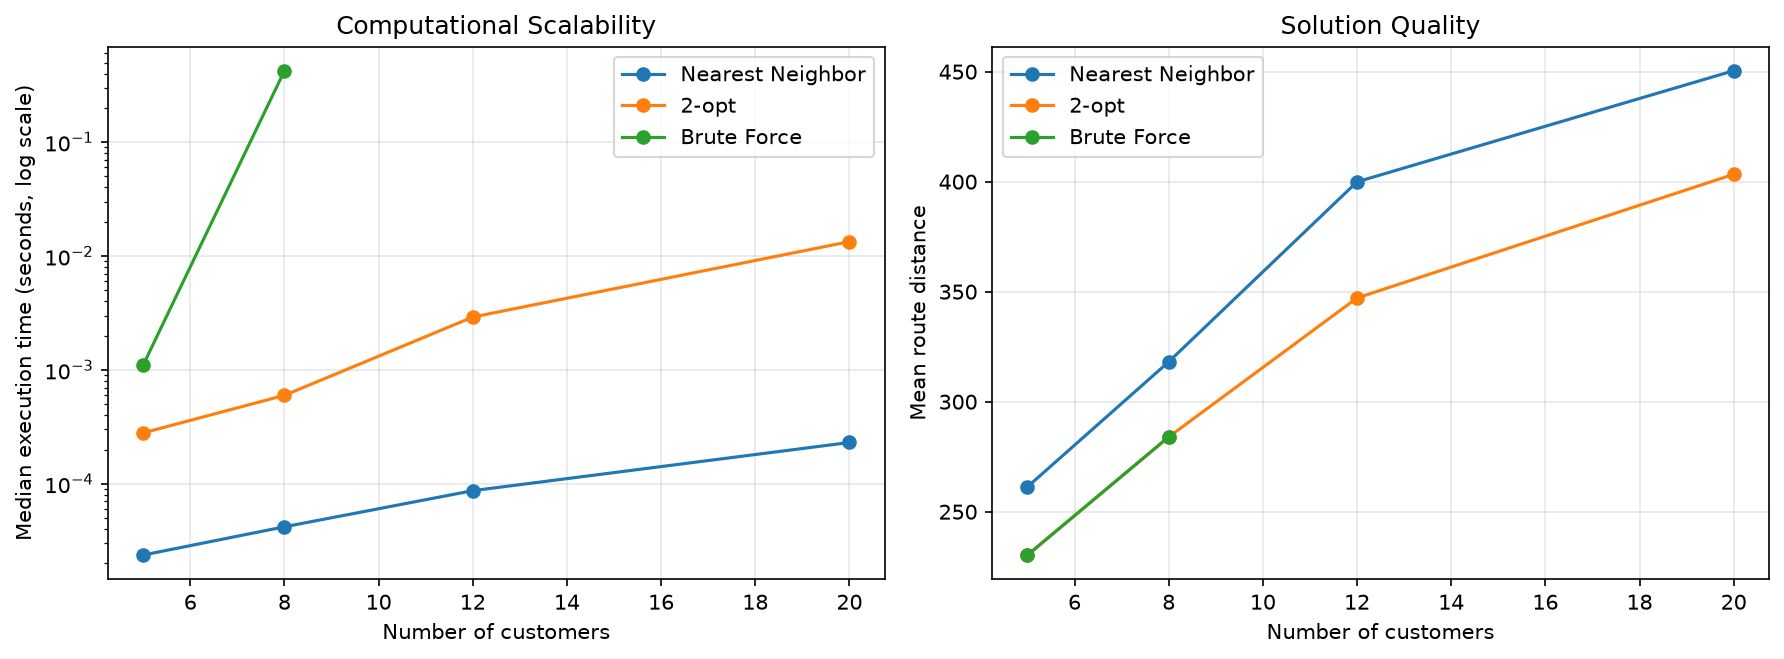

In [6]:
from IPython.display import Image, display
display(Image(filename=str(PROJECT_ROOT / 'results' / 'algorithm_benchmark.png'))) 

## Discussion

This section should be completed after inspecting the generated table and figure. Compare mean distance, median runtime, exact gaps for 5–8 customers, and the size at which exact search is no longer practical.

## Conclusions

The conclusions will be based on the measured results. Do not describe a gap as exact for problem sizes where the exact optimum was not computed.

## Development Decisions

Record whether 2-opt should remain the construction-improvement baseline, be extended with best-improvement search, or be replaced for larger instances.

## Next Steps

1. Repeat with more seeds and larger customer counts.
2. Implement randomized starting points or alternative heuristics.
3. Validate route feasibility and replicate results from saved CSV data.
4. Continue toward Google OR-Tools integration in Phase 4.